# Experiment 4 — Hill climbing
CSAI4014 AISR Laboratory · Lab Manual, Chapter 5

(1) a 1-D landscape with several local maxima and hill climbs that get trapped, (2) steepest-ascent hill
climbing on eight queens, (3) random restarts compared with the prediction 1 − (1 − p)^k.

In [1]:
import json, os, platform, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figs", exist_ok=True)
RESULTS = {}                      # every number the report quotes is stored here

def save(fig, name):
    """Save a figure into figs/ (150 dpi PNG, as the report guidelines ask)."""
    fig.savefig(os.path.join("figs", name), bbox_inches="tight")

def env_info():
    info = {"python": platform.python_version(), "numpy": np.__version__,
            "matplotlib": matplotlib.__version__, "os": f"{platform.system()} {platform.release()}",
            "cpu": platform.processor() or platform.machine()}
    try:
        import scipy; info["scipy"] = scipy.__version__
    except ImportError:
        pass
    return info

RESULTS["env"] = env_info()
print(RESULTS["env"])

{'python': '3.12.1', 'numpy': '2.3.2', 'matplotlib': '3.8.4', 'os': 'Windows 11', 'cpu': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'scipy': '1.16.1'}


## 1. Seeing the landscape

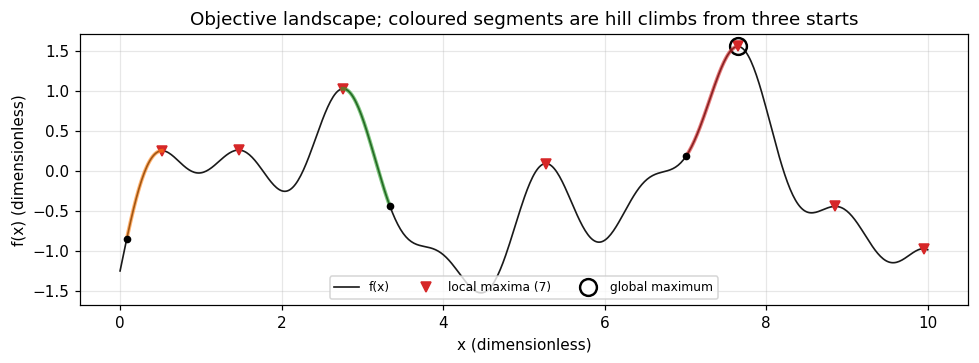

start x = 0.08 -> stops at x = 0.52, f = 0.250 (local maximum)
start x = 3.34 -> stops at x = 2.75, f = 1.023 (local maximum)
start x = 7.01 -> stops at x = 7.65, f = 1.550 (global maximum)


In [2]:
def f1(x):
    return np.sin(x) + 0.6*np.sin(2.7*x) + 0.35*np.sin(5.1*x) - 0.05*(x - 5)**2

xs = np.linspace(0, 10, 600)
fx = f1(xs)
# local maxima: grid points higher than both neighbours
imax = np.where((fx[1:-1] > fx[:-2]) & (fx[1:-1] > fx[2:]))[0] + 1
iglob = int(np.argmax(fx))

def hill_climb_1d(i):
    """Discrete steepest ascent on the sampled landscape: step to the higher neighbour."""
    path = [i]
    while True:
        cand = [j for j in (i - 1, i + 1) if 0 <= j < xs.size]
        j = max(cand, key=lambda j: fx[j])
        if fx[j] <= fx[i]:
            return path
        i = j; path.append(i)

starts = [5, 200, 420]                       # three starting points
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(xs, fx, lw=1.1, color="0.1", label="f(x)")
ax.plot(xs[imax], fx[imax], "v", color="tab:red", ms=7, label=f"local maxima ({len(imax)})")
ax.plot(xs[iglob], fx[iglob], "o", ms=11, mfc="none", mec="k", mew=1.6, label="global maximum")
for s in starts:
    p = hill_climb_1d(s)
    ax.plot(xs[p], fx[p], lw=2.5, alpha=0.6)
    ax.plot(xs[s], fx[s], "k.", ms=8)
ax.set(xlabel="x (dimensionless)", ylabel="f(x) (dimensionless)",
       title="Objective landscape; coloured segments are hill climbs from three starts")
ax.legend(fontsize=8, loc="lower center", ncol=3)
fig.tight_layout(); save(fig, "fig4_1_landscape.png"); plt.show()

ends = [hill_climb_1d(s)[-1] for s in starts]
for s, e in zip(starts, ends):
    print(f"start x = {xs[s]:.2f} -> stops at x = {xs[e]:.2f}, f = {fx[e]:.3f} "
          f"({'global' if e == iglob else 'local'} maximum)")
RESULTS["landscape"] = {"local_maxima_x": xs[imax].round(2).tolist(),
                        "global_x": float(xs[iglob]), "global_f": float(fx[iglob])}

## 2. Hill climbing on eight queens

In [3]:
import random

def conflicts(board):  # from Experiment 2
    n = len(board); bad = 0
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                bad += 1
    return bad

def hill_climb(n=8, seed=0):
    """Steepest ascent (minimising conflicts). Returns True if a conflict-free board is reached."""
    r = random.Random(seed)
    board = [r.randrange(n) for _ in range(n)]  # a complete, random board
    while True:
        current = conflicts(board)
        if current == 0:
            return True                         # solved
        best, move = current, None
        for c in range(n):                      # try every single-queen move
            old = board[c]
            for row in range(n):
                if row == old:
                    continue
                board[c] = row
                v = conflicts(board)
                if v < best:
                    best, move = v, (c, row)
            board[c] = old
        if move is None:
            return False                        # local minimum: stuck
        board[move[0]] = move[1]

TRIALS = 200
succ = sum(hill_climb(8, seed=s) for s in range(TRIALS))
p = succ / TRIALS
print(f"plain hill climbing: {succ}/{TRIALS} = {100*p:.1f}% of random starts")
RESULTS["plain"] = {"trials": TRIALS, "successes": succ, "p": p}

plain hill climbing: 25/200 = 12.5% of random starts


## 3. Random restarts

  1 restarts: 29/200 =  14.5%   predicted  12.5%
  2 restarts: 51/200 =  25.5%   predicted  23.4%
  5 restarts: 112/200 =  56.0%   predicted  48.7%
 10 restarts: 156/200 =  78.0%   predicted  73.7%
 20 restarts: 195/200 =  97.5%   predicted  93.1%
restarts needed for 99 %: 35;  standard error of p with 200 trials = 2.3 points


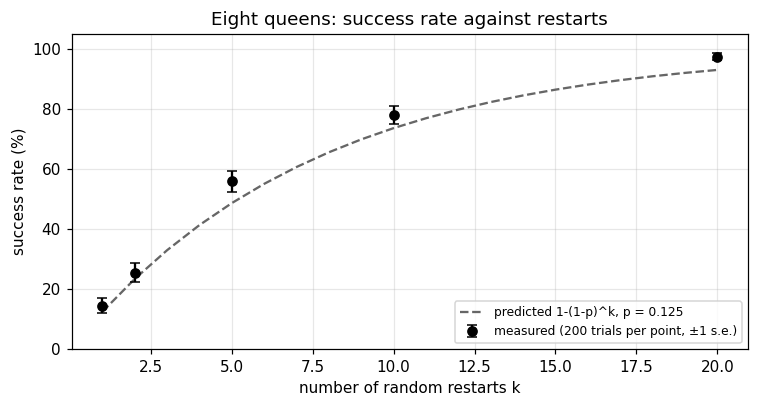

In [4]:
def hill_climb_restarts(n=8, restarts=10, seed=0):
    for k in range(restarts):
        if hill_climb(n, seed=seed*1000 + k):
            return True
    return False

KS = (1, 2, 5, 10, 20)
rows = []
for k in KS:
    ok = sum(hill_climb_restarts(8, k, seed=1000 + s) for s in range(TRIALS))
    pred = 1 - (1 - p)**k
    rows.append({"k": k, "trials": TRIALS, "successes": ok, "measured": ok/TRIALS, "predicted": pred})
    print(f"{k:>3} restarts: {ok}/{TRIALS} = {100*ok/TRIALS:5.1f}%   predicted {100*pred:5.1f}%")
RESULTS["restarts"] = rows
k99 = int(np.ceil(np.log(0.01) / np.log(1 - p)))
RESULTS["k_for_99"] = k99
se = np.sqrt(p*(1 - p)/TRIALS)
RESULTS["p_std_err"] = se
print(f"restarts needed for 99 %: {k99};  standard error of p with {TRIALS} trials = {100*se:.1f} points")

kk = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(kk, 100*(1 - (1 - p)**kk), "--", color="0.4", label=f"predicted 1-(1-p)^k, p = {p:.3f}")
ax.errorbar(KS, [100*r["measured"] for r in rows],
            yerr=[100*np.sqrt(r["measured"]*(1-r["measured"])/TRIALS) for r in rows],
            fmt="o", color="k", capsize=3, label=f"measured ({TRIALS} trials per point, ±1 s.e.)")
ax.set(xlabel="number of random restarts k", ylabel="success rate (%)", ylim=(0, 105),
       title="Eight queens: success rate against restarts")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); save(fig, "fig4_2_restarts.png"); plt.show()

In [5]:
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("saved results.json and", len(os.listdir("figs")), "figures in figs/")

saved results.json and 2 figures in figs/
